# Task 1C: Training a model (hourly electricity demand, Spain)

**Goal:** predict electricity demand (`total load actual`, MW) from recent load, the clock and the temperature.

**Data:** `energy_weather_features.csv`, produced by the EDA notebook (`notebooks/01_preprocessing_eda.ipynb`) (hourly, 2015-2018).

**Split:** chronological. Train = 2015-2017, test = 2018. No shuffling, so the model never sees the future.

**Experiments**

| # | Model | Features | Task |
|---|---|---|---|
| 0 | Naive (same as last hour) | none | next hour |
| 1 | Linear Regression, calendar as plain integers | calendar + lags | next hour |
| 2 | Linear Regression, calendar one-hot encoded | calendar + lags | next hour |
| 3 | Linear Regression, one-hot | + moving averages + temperature | next hour |
| 4 | Random Forest (default) | all features | next hour |
| 5 | Random Forest (tuned with `TimeSeriesSplit`) | all features | next hour |
| 6 | Random Forest (tuned settings), no `lag_1` and no moving averages | calendar + lag 24 / 168 + temperature | day ahead |

Experiments 1 and 2 differ only in how `dayofweek` and `month` are encoded, so the gap between them shows how much of Linear Regression's weakness comes from the encoding rather than from the model itself. Experiment 6 is a harder, day-ahead version of the problem (no information from the last 23 hours), which is the setting the operator's own forecast works in.

## 1. Imports

In [1]:
import os
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## 2. Load the data


In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "outputs" / "processed" / "energy_weather_features.csv"
OUT_DIR = ROOT / "outputs" / "model"
MODEL_DIR = ROOT / "models"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not DATA_PATH.exists():
    if IN_COLAB:
        files.upload()
        DATA_PATH = Path("energy_weather_features.csv")
    else:
        raise FileNotFoundError(f"{DATA_PATH} not found. Run the EDA notebook first to create it.")
print("Using data file:", DATA_PATH)


Using data file: energy_weather_features.csv


## 3. Settings

In [3]:
TARGET = "total load actual"
OPERATOR_FORECAST = "total load forecast"
SPLIT_DATE = pd.Timestamp("2018-01-01", tz="UTC")
RANDOM_STATE = 42

## 4. Load and clean the data
Rows where the target was missing (36 hours) are removed, because their value was filled in by interpolation.And the first week has no lag history yet, so it is removed too. Lastly,the notebook first checks that every column it needs is in the CSV, to avoid mismatch


In [4]:
df = pd.read_csv(DATA_PATH, index_col="time")
df.index = pd.to_datetime(df.index, utc=True)
df = df.sort_index()

lag_cols = ["load_lag_1", "load_lag_24", "load_lag_168", "load_ma_24", "load_ma_168"]
required = [TARGET, "hour", "dayofweek", "month", "is_weekend", "temp_mean"] + lag_cols
missing_cols = [c for c in required if c not in df.columns]
assert not missing_cols, f"These columns are missing from the CSV (re-export it from the EDA notebook): {missing_cols}"

if "target_was_missing" in df.columns:
    df = df[df["target_was_missing"] == 0]
else:
    print("WARNING: 'target_was_missing' is not in the CSV, so interpolated target rows are NOT removed. "
          "Add this flag in the EDA notebook for a cleaner evaluation.")

df = df.dropna(subset=lag_cols)
print("Rows after cleaning:", len(df))

Rows after cleaning: 34866


## 5. Feature engineering
* `hour_sin` / `hour_cos`: the hour as a circle, so 23:00 and 00:00 are close together.
* `heating_deg` / `cooling_deg`: distance from 17 °C. The EDA showed demand is lowest near 17 °C and rises on both sides.

**Left out on purpose:** the generation columns (they add up to the load, so they leak the answer), the operator's own load forecast (the model would just copy it), prices, and `year`.

**Feature sets**
* `BASE_FEATURES`: calendar + lags.
* `FEATURES`: base + moving averages + temperature (next-hour model).
* `DAYAHEAD_FEATURES`: nothing newer than 24 hours old. The moving averages are shifted by one hour, so they contain the last 23 hours and cannot be used day-ahead.

In [5]:
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["heating_deg"] = (17 - df["temp_mean"]).clip(lower=0)
df["cooling_deg"] = (df["temp_mean"] - 17).clip(lower=0)

CALENDAR_CATEGORICAL = ["dayofweek", "month"]

BASE_FEATURES = ["hour_sin", "hour_cos", "dayofweek", "month", "is_weekend",
                 "load_lag_1", "load_lag_24", "load_lag_168"]
FEATURES = BASE_FEATURES + ["load_ma_24", "load_ma_168", "temp_mean", "heating_deg", "cooling_deg"]
DAYAHEAD_FEATURES = ["hour_sin", "hour_cos", "dayofweek", "month", "is_weekend",
                     "load_lag_24", "load_lag_168", "temp_mean", "heating_deg", "cooling_deg"]

## 6. Chronological train / test split

In [6]:
train = df[df.index < SPLIT_DATE]
test = df[df.index >= SPLIT_DATE]
y_train, y_test = train[TARGET], test[TARGET]

print(f"Train: {train.index.min():%Y-%m-%d} to {train.index.max():%Y-%m-%d}  ({len(train):,} rows)")
print(f"Test : {test.index.min():%Y-%m-%d} to {test.index.max():%Y-%m-%d}  ({len(test):,} rows)")

Train: 2015-01-07 to 2017-12-31  (26,109 rows)
Test : 2018-01-01 to 2018-12-31  (8,757 rows)


## 7. Helpers

In [7]:
def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mape = float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100)
    return round(mae, 2), round(rmse, 2), round(mape, 2)


def make_linreg(cols, one_hot):
    """Linear Regression with standardised numbers. If one_hot, dayofweek and month become dummy columns."""
    cat = [c for c in CALENDAR_CATEGORICAL if c in cols] if one_hot else []
    num = [c for c in cols if c not in cat]
    parts = [("num", StandardScaler(), num)]
    if cat:
        parts.append(("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat))
    return Pipeline([("prep", ColumnTransformer(parts)), ("lr", LinearRegression())])


rows = []
predictions = {}

## 8. Experiment 0: naive baseline
Predict that the next hour equals the last hour. Any real model has to beat this.

In [8]:
predictions["0 Naive"] = test["load_lag_1"].to_numpy()
rows.append(["0 Naive", "last hour's load", "load_lag_1", "-", "next hour", *evaluate(y_test, predictions["0 Naive"])])

## 9. Experiments 1-3: Linear Regression
The scaler is fitted inside the pipeline on the training years only.
Experiment 1 keeps `dayofweek` and `month` as plain numbers (a straight line through Monday to Sunday and January to December). Experiments 2 and 3 one-hot encode them, which is the fair way to give a linear model calendar information.

In [9]:
lin_experiments = [
    ("1 LinReg base (int calendar)", BASE_FEATURES, False, "calendar (integers) + lags"),
    ("2 LinReg base (one-hot)",      BASE_FEATURES, True,  "calendar (one-hot) + lags"),
    ("3 LinReg full (one-hot)",      FEATURES,      True,  "calendar (one-hot) + lags + moving averages + temperature"),
]
for name, cols, one_hot, desc in lin_experiments:
    model = make_linreg(cols, one_hot).fit(train[cols], y_train)
    predictions[name] = model.predict(test[cols])
    rows.append([name, "LinearRegression", desc, "defaults", "next hour", *evaluate(y_test, predictions[name])])

## 10. Experiment 4: Random Forest with default settings

In [10]:
rf_default = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)
rf_default.fit(train[FEATURES], y_train)
predictions["4 RF default"] = rf_default.predict(test[FEATURES])
rows.append(["4 RF default", "RandomForest", "all features", "n_estimators=100", "next hour",
             *evaluate(y_test, predictions["4 RF default"])])

## 11. Experiment 5: Random Forest with hyperparameter tuning
`RandomizedSearchCV` tries 8 random combinations of the settings below. Each one is scored with `TimeSeriesSplit` (4 folds): every fold trains on the past and validates on the block that follows, so the tuning never looks at the future. Only the training years (2015-2017) are used for tuning. The first fold trains on roughly the first fifth of the data, which is less than one full year, so early folds are noisier than later ones.

The grid limits the tree depth (15-25) and the leaf size (3-10) on purpose: fully grown trees make a model file of several hundred MB, which is too big to commit to GitHub. I did not train a fully grown forest, so this notebook does not measure how much accuracy the limit costs.

In [11]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [15, 20, 25],
    "min_samples_leaf": [3, 5, 10],
    "max_features": [0.5, 1.0],
}

search = RandomizedSearchCV(
    RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE),
    param_distributions=param_grid,
    n_iter=8,
    cv=TimeSeriesSplit(n_splits=4),
    scoring="neg_mean_absolute_error",
    random_state=RANDOM_STATE,
    verbose=1,
)
search.fit(train[FEATURES], y_train)

best_rf = search.best_estimator_
predictions["5 RF tuned"] = best_rf.predict(test[FEATURES])
rows.append(["5 RF tuned", "RandomForest", "all features", str(search.best_params_), "next hour",
             *evaluate(y_test, predictions["5 RF tuned"])])

print("Best settings:", search.best_params_)
print(f"Best cross-validation MAE (training years only): {-search.best_score_:.1f} MW")

Fitting 4 folds for each of 8 candidates, totalling 32 fits
Best settings: {'n_estimators': 200, 'min_samples_leaf': 3, 'max_features': 1.0, 'max_depth': 25}
Best cross-validation MAE (training years only): 388.7 MW


### All the settings that were tried

In [12]:
tuning_table = (pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "rank_test_score"]]
                .assign(cv_MAE_MW=lambda t: (-t["mean_test_score"]).round(1))
                .drop(columns="mean_test_score")
                .sort_values("rank_test_score"))
tuning_table

,params,rank_test_score,cv_MAE_MW
5,"{'n_estimators': 200, 'min_samples_leaf': 3, '...",1,388.7
3,"{'n_estimators': 100, 'min_samples_leaf': 3, '...",2,389.3
6,"{'n_estimators': 200, 'min_samples_leaf': 5, '...",3,393.8
0,"{'n_estimators': 200, 'min_samples_leaf': 10, ...",4,410.5
1,"{'n_estimators': 200, 'min_samples_leaf': 3, '...",5,412.1
7,"{'n_estimators': 100, 'min_samples_leaf': 3, '...",6,415.6
2,"{'n_estimators': 100, 'min_samples_leaf': 5, '...",7,424.7
4,"{'n_estimators': 100, 'min_samples_leaf': 10, ...",8,453.4


## 12. Experiment 6: day-ahead Random Forest
Same tuned settings as experiment 5, but the model may only use information that is at least 24 hours old (`load_lag_24`, `load_lag_168`, the clock and the temperature). This is the harder problem the operator's day-ahead forecast solves, so it is the fair comparison with the operator. The temperature is the temperature of the hour being predicted, so in real use it would come from a weather forecast.

In [13]:
rf_dayahead = clone(best_rf).fit(train[DAYAHEAD_FEATURES], y_train)
predictions["6 RF day-ahead"] = rf_dayahead.predict(test[DAYAHEAD_FEATURES])
rows.append(["6 RF day-ahead", "RandomForest", "no lag_1, no moving averages", str(search.best_params_), "day ahead",
             *evaluate(y_test, predictions["6 RF day-ahead"])])

benchmarks = {"Same hour yesterday (lag 24)": test["load_lag_24"].to_numpy()}
if OPERATOR_FORECAST in test.columns:
    benchmarks["Operator day-ahead forecast"] = test[OPERATOR_FORECAST].to_numpy()
else:
    print(f"Note: '{OPERATOR_FORECAST}' is not in the CSV, so the operator benchmark is skipped.")

bench_table = pd.DataFrame(
    [[name, *evaluate(y_test, pred)] for name, pred in benchmarks.items()],
    columns=["Benchmark", "MAE (MW)", "RMSE (MW)", "MAPE (%)"]).set_index("Benchmark")
bench_table

,MAE (MW),RMSE (MW),MAPE (%)
Benchmark,,,
Same hour yesterday (lag 24),2519.16,3606.59,8.72
Operator day-ahead forecast,269.80,389.29,0.93


## 13. Experiment table (test set = 2018)

In [14]:
results = pd.DataFrame(rows, columns=["Experiment", "Model", "Features", "Settings", "Task",
                                      "MAE (MW)", "RMSE (MW)", "MAPE (%)"]).set_index("Experiment")
results.to_csv(f"{OUT_DIR}/model_experiments.csv")
tuning_table.to_csv(f"{OUT_DIR}/rf_tuning_results.csv", index=False)
bench_table.to_csv(f"{OUT_DIR}/day_ahead_benchmarks.csv")
results

,Model,Features,Settings,Task,MAE (MW),RMSE (MW),MAPE (%)
Experiment,,,,,,,
0 Naive,last hour's load,load_lag_1,-,next hour,1076.29,1438.34,3.78
1 LinReg base (int calendar),LinearRegression,calendar (integers) + lags,defaults,next hour,865.99,1150.17,2.98
2 LinReg base (one-hot),LinearRegression,calendar (one-hot) + lags,defaults,next hour,865.03,1148.10,2.98
3 LinReg full (one-hot),LinearRegression,calendar (one-hot) + lags + moving averages + ...,defaults,next hour,853.28,1139.24,2.94
4 RF default,RandomForest,all features,n_estimators=100,next hour,343.59,561.39,1.19
5 RF tuned,RandomForest,all features,"{'n_estimators': 200, 'min_samples_leaf': 3, '...",next hour,342.65,557.29,1.18
6 RF day-ahead,RandomForest,"no lag_1, no moving averages","{'n_estimators': 200, 'min_samples_leaf': 3, '...",day ahead,1727.93,2549.74,5.96


## 14. Plots

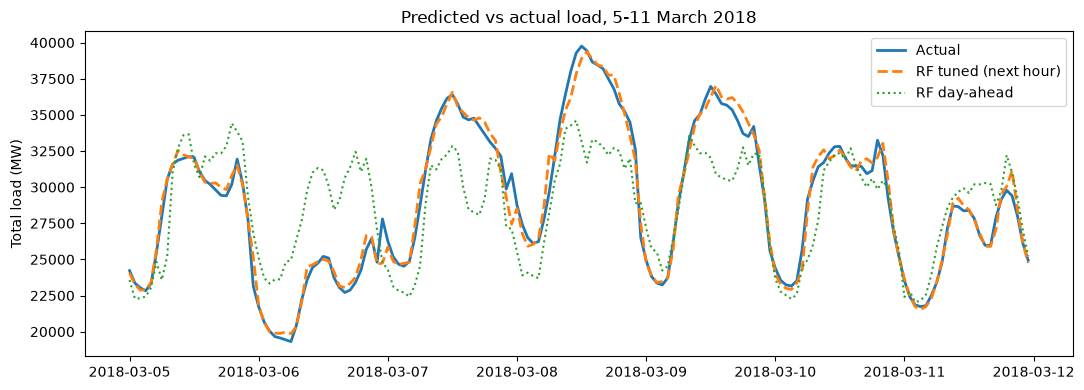

In [15]:
# Predicted vs actual for one week of the test year
week = slice("2018-03-05", "2018-03-11")
pred_tuned = pd.Series(predictions["5 RF tuned"], index=test.index)
pred_dayahead = pd.Series(predictions["6 RF day-ahead"], index=test.index)

plt.figure(figsize=(11, 4))
plt.plot(y_test.loc[week], label="Actual", lw=2)
plt.plot(pred_tuned.loc[week], label="RF tuned (next hour)", lw=2, ls="--")
plt.plot(pred_dayahead.loc[week], label="RF day-ahead", lw=1.5, ls=":")
plt.title("Predicted vs actual load, 5-11 March 2018")
plt.ylabel("Total load (MW)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/pred_vs_actual_week.png", dpi=150)
plt.show()

**Interpretation**

- The tuned next-hour model (orange dashed) sits almost on top of the actual load (blue). It follows the sharp morning rise and the evening drop on every day of the week, which fits its test MAE of about 343 MW.
- Where it is wrong, it is wrong in the same way each time: at the turning points the orange line arrives about one hour after the blue one. This happens because the model relies mostly on the previous hour (see the feature importance plot below).
- The day-ahead model (green dotted) gets the general level of demand but misses the daily peaks and dips. On 8 March, for example, it stays around 34,000 MW while actual demand reaches almost 40,000 MW.
- This is why the day-ahead error is much higher (MAE 1,728 MW): that model has no information from the last 23 hours.

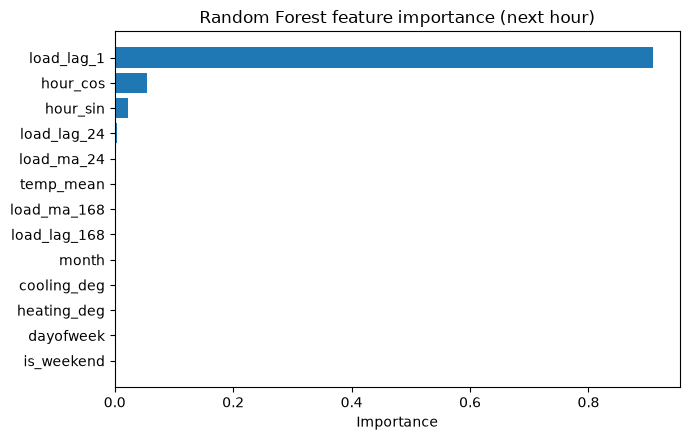

In [16]:
# features the tuned Random Forest use most
importance = pd.Series(best_rf.feature_importances_, index=FEATURES).sort_values()

plt.figure(figsize=(7, 4.5))
plt.barh(importance.index, importance.values)
plt.title("Random Forest feature importance (next hour)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/feature_importance.png", dpi=150)
plt.show()

**Interpretation**

- `load_lag_1` carries about 91% of the importance. The cyclical hour features come next (`hour_cos` about 5%, `hour_sin` about 2%), and every other feature is close to zero.
- In plain words, the model predicts next hour's demand mostly from this hour's demand, adjusted for the time of day. This agrees with Question 3 of the EDA, where lag 1 had a correlation of 0.95.
- A low importance does not mean a feature is useless. Temperature clearly affects demand (EDA Question 5), but its effect is already contained in the previous hour's load, so the forest has little left to credit to it.
- The risk of this design is that the model depends on one input. Without `load_lag_1` it performs much worse, which is what experiment 6 (day-ahead) shows.

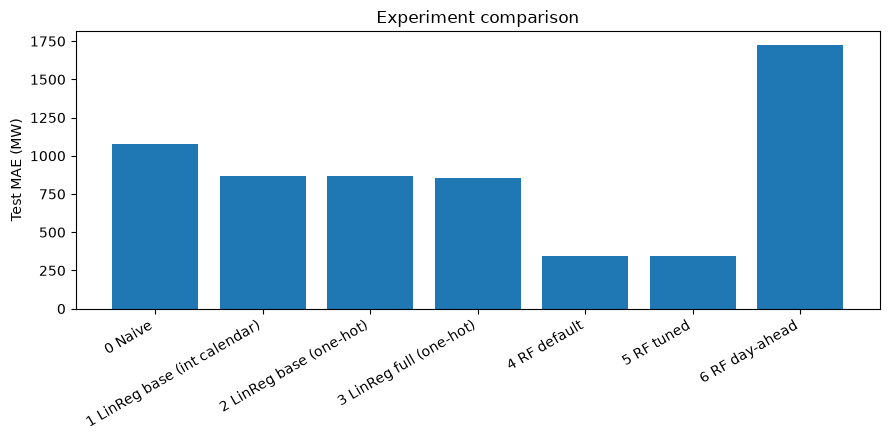

In [17]:
# Error of each experiment, side by side
plt.figure(figsize=(9, 4.5))
plt.bar(results.index, results["MAE (MW)"])
plt.ylabel("Test MAE (MW)")
plt.title("Experiment comparison")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/experiment_comparison.png", dpi=150)
plt.show()

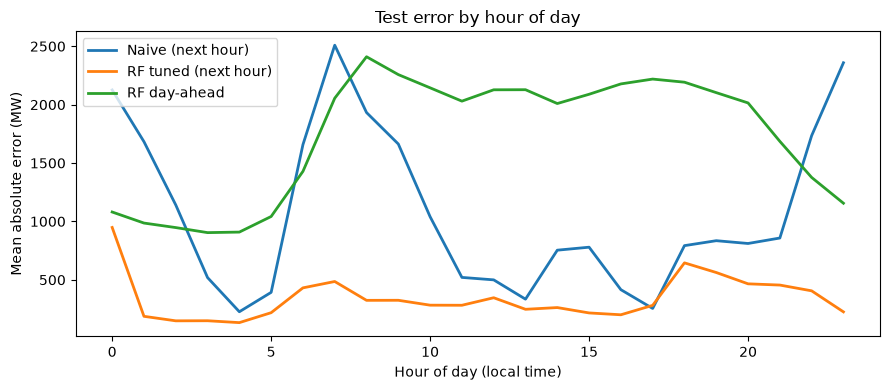

In [18]:
# Average error for each hour of the day (local Spanish time)
hours = test.index.tz_convert("Europe/Madrid").hour
abs_err = pd.DataFrame({
    "Naive (next hour)": np.abs(y_test.to_numpy() - predictions["0 Naive"]),
    "RF tuned (next hour)": np.abs(y_test.to_numpy() - predictions["5 RF tuned"]),
    "RF day-ahead": np.abs(y_test.to_numpy() - predictions["6 RF day-ahead"]),
}, index=test.index)
abs_err.groupby(hours).mean().plot(figsize=(9, 4), lw=2)
plt.xlabel("Hour of day (local time)")
plt.ylabel("Mean absolute error (MW)")
plt.title("Test error by hour of day")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/error_by_hour.png", dpi=150)
plt.show()

## 15. Save the final model for the forecast script 
The next-hour tuned forest (experiment 5) is saved.

In [19]:
MODEL_PATH = f"{MODEL_DIR}/best_rf_model.joblib"
joblib.dump({"model": best_rf, "features": FEATURES, "target": TARGET}, MODEL_PATH, compress=3)

size_mb = os.path.getsize(MODEL_PATH) / 1e6
print(f"Model file size: {size_mb:.1f} MB")
if size_mb > 95:
    print("TOO BIG for GitHub (limit 100 MB). Lower n_estimators or raise min_samples_leaf, or use Git LFS.")
elif size_mb > 50:
    print("Warning: large file. GitHub will warn above 50 MB; consider a smaller forest or Git LFS.")

with open(f"{MODEL_DIR}/feature_list.json", "w") as f:
    json.dump({"features": FEATURES, "target": TARGET, "horizon": "next hour",
               "best_params": search.best_params_,
               "needs": "last 168 hourly loads, local calendar fields, mean temperature of the five cities"},
              f, indent=2)
print("Saved model and feature_list.json in", MODEL_DIR)

Model file size: 36.7 MB
Saved model and feature_list.json in task1c_outputs


## 16. Results summary 
The numbers below are generated from the results table and they always match the run above.

In [20]:
mae = results["MAE (MW)"]
best_next = mae[["4 RF default", "5 RF tuned"]].idxmin()
pct = lambda new, old: 100 * (old - new) / old
top_feat = importance.sort_values(ascending=False)

print(f"Next-hour: best Random Forest is '{best_next}' with MAE {mae[best_next]:,.0f} MW "
      f"({results.loc[best_next, 'MAPE (%)']:.2f} %).")
def vs(ref_name, ref):
    d = pct(mae[best_next], ref)
    return f"  vs {ref_name} ({ref:,.0f} MW): {abs(d):.0f} % {'lower' if d >= 0 else 'HIGHER'} error."
print(vs("naive baseline", mae["0 Naive"]))
best_lin = mae[["2 LinReg base (one-hot)", "3 LinReg full (one-hot)"]].min()
print(vs("best Linear Regression", best_lin))
print()
print(f"Calendar encoding: integer {mae['1 LinReg base (int calendar)']:,.0f} MW -> one-hot "
      f"{mae['2 LinReg base (one-hot)']:,.0f} MW "
      f"({pct(mae['2 LinReg base (one-hot)'], mae['1 LinReg base (int calendar)']):.0f} % change).")
print(f"Moving averages + temperature for Linear Regression: {mae['2 LinReg base (one-hot)']:,.0f} MW -> "
      f"{mae['3 LinReg full (one-hot)']:,.0f} MW.")
print(f"Tuning: default forest {mae['4 RF default']:,.0f} MW vs tuned forest {mae['5 RF tuned']:,.0f} MW "
      f"(difference {mae['4 RF default'] - mae['5 RF tuned']:+,.0f} MW).")
print(f"Most important feature: {top_feat.index[0]} ({100 * top_feat.iloc[0]:.0f} % of importance), "
      f"then {top_feat.index[1]} ({100 * top_feat.iloc[1]:.0f} %).")
print()
print(f"Day-ahead forest (experiment 6): MAE {mae['6 RF day-ahead']:,.0f} MW.")
for name, row in bench_table.iterrows():
    print(f"  benchmark '{name}': MAE {row['MAE (MW)']:,.0f} MW")

Next-hour: best Random Forest is '5 RF tuned' with MAE 343 MW (1.18 %).
  vs naive baseline (1,076 MW): 68 % lower error.
  vs best Linear Regression (853 MW): 60 % lower error.

Calendar encoding: integer 866 MW -> one-hot 865 MW (0 % change).
Moving averages + temperature for Linear Regression: 865 MW -> 853 MW.
Tuning: default forest 344 MW vs tuned forest 343 MW (difference +1 MW).
Most important feature: load_lag_1 (91 % of importance), then hour_cos (5 %).

Day-ahead forest (experiment 6): MAE 1,728 MW.
  benchmark 'Same hour yesterday (lag 24)': MAE 2,519 MW
  benchmark 'Operator day-ahead forecast': MAE 270 MW


## 17. Interpretation

* **Random Forest vs the baselines.** The tuned forest has a test MAE of 343 MW (1.18 %), against 1,076 MW for the naive "same as last hour" baseline (68 % lower) and 853 MW for the best Linear Regression (60 % lower).
* **Linear Regression and the calendar.** One-hot encoding `dayofweek` and `month` changed almost nothing (866 to 865 MW), so the gap to the forest is not caused by how the calendar was encoded. Adding moving averages and temperature helped only a little (865 to 853 MW). The likely reason is that demand depends on combinations (hour x weekday, and the V-shaped temperature response) that a model adding up independent effects cannot represent. This was not tested directly.
* **Tuning made almost no difference.** The default forest scores 344 MW and the tuned one 343 MW. The best settings (depth 25, leaf size 3, `max_features` 1.0) sit at the edge of the grid, so a bigger forest might gain a little; I capped depth and leaf size to keep the saved model small (36.7 MB), and did not train an unrestricted forest, so the cost of the cap is not measured. The cross-validation MAE (about 389 MW) is higher than the 2018 test MAE because the early folds train on less than a year of data.
* **The previous hour dominates.** `load_lag_1` carries 91 % of the feature importance, followed by `hour_cos` (5 %). In the week plot the next-hour forecast follows the actual curve closely but trails it by about an hour, which is what a model leaning on the last hour does. Temperature and moving averages add little once the last hour is known.
* **Next hour vs day ahead.** With no information from the last 23 hours, the forest's error rises to 1,728 MW (5.96 %). That is 31 % better than "same hour yesterday" (2,519 MW) but about 6 times worse than the operator's day-ahead forecast (270 MW on 2018). The next-hour forest (343 MW) is also worse than the operator even though its task is easier. So the model clearly beats simple baselines, but it does not replace the operator's forecast.
* **Limits.** (1) Public holidays are not marked in the data, so they likely cause some of the larger errors. (2) The temperature used is that of the hour being predicted; in real use it would be a weather forecast. (3) Rows whose own target was interpolated were removed, but features built from interpolated hours were kept. (4) Four years of data from one country, and a single test year.
